Re-run this notebook from anywhere inside the repository with:

```bash
(cd "$(git rev-parse --show-toplevel)" && uv run --no-project --with jupyter --with pyyaml --with pandas --with numpy --with scipy --with matplotlib --with openai --with python-dotenv --with requests jupyter nbconvert --to notebook --execute --inplace explorations/notebooks/05_model_trial.ipynb)
```

# 05 · Model trial through OpenRouter (experiment E13, PRELIMINARY)

**Question.** Which model should the pipeline's item classifier use, and which confidence
signal should drive the EXC-03 "uncertain item" threshold?

**Candidates**, all through OpenRouter, the gateway the brief provides:

- **10 generative models.** They are asked for a strict JSON answer: a category and a
  self-reported confidence (prompt `cls-v1`).
- **5 decision models.** They return a choice plus a probability distribution over the 21
  categories instead of text (prompt `dec-v1`, POST `/api/alpha/decisions`).

**What is held fixed:**
- the 109 synthetic dev items, with DRAFT labels;
- the input: item text, merchant and MCC;
- temperature 0, except the two endpoints that reject it (see the deviations below);
- one pinned endpoint per generative model;
- every answer cached, with its OpenRouter request id.

**The decision rule was written and committed before any of these runs**, as experiment E13 in
`research/experiments_plan.yaml`. This notebook applies it mechanically.

Every result here is **PRELIMINARY**. The labels are drafts written by the same assistant that
wrote the prompts, and an earlier trial showed this set barely separates strong models.

In [1]:
from __future__ import annotations

import json
import math
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import display
from scipy import stats

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "policy-docs").is_dir())
EXP = REPO / "explorations"
sys.path.insert(0, str(EXP / "lib"))
import classifier_prompt as cp
import run_trial

plan = yaml.safe_load((EXP / "research" / "experiments_plan.yaml").read_text())
E13 = next(e for e in plan["experiments"] if e["id"] == "E13")
print("registered at:", E13["registered_at"])
print("\nDECISION RULE (as registered):\n" + E13["decision_rule"])
print("\nDEVIATIONS:\n- " + "\n- ".join(E13.get("deviations", [])))

registered at: 2026-10-09T02:05:34+00:00

DECISION RULE (as registered):
(1) Exclude any model with a schema-valid rate below 0.98 or an error rate above 2 %. (2) Reference: openai/gpt-oss-120b (the current choice). A challenger replaces it only if McNemar exact p < 0.05 in its favour on correctness and its restricted F1 is not lower. Otherwise, among models not significantly worse than the reference (McNemar p >= 0.05, or better), choose the cheapest per 1,000 items, then the lowest median latency. (3) EXC-03 confidence source: the lowest Brier score (top-label confidence vs correctness) among non-excluded models; report ECE and a reliability table with bin counts. (4) The labels are DRAFT and the set saturated earlier models, so the outcome is PRELIMINARY and must be re-run on the hardened, Luis-reviewed dev set before it is final.

DEVIATIONS:
- 2026-10-09: the pinned endpoints of anthropic/claude-haiku-5.5 (google-vertex/global) and openai/gpt-6-luna (openai) do not accept `tempera

## How these runs were produced

The model calls are **not made inside this notebook**. They were made by a script, so 1,635
calls could run in parallel, resume after interruptions, and be cached. This notebook only
reads what that script stored.

The call path, with each file under `explorations/`:

1. `scripts/run_e13.py` runs every pre-registered model (`research/openrouter_models.json`),
   five at a time, in three passes. Later passes only retry transient provider errors.
2. `lib/run_trial.py` classifies the 109 dev items with one model and writes one row per item
   to `results/trial_runs/openrouter__<model>.jsonl`.
3. `lib/decision_adapters.py` builds the request:
   - `ChatJSONClassifier`: system and user messages with a strict JSON schema;
   - `DecisionClassifier`: a decision payload.
4. `lib/budget.py` sends it to OpenRouter:
   - pins the chat model's endpoint (`research/openrouter_pins.json`);
   - enforces the spend cap;
   - caches the answer;
   - logs the call in `results/budget_log.jsonl`;
   - saves the raw response body under `raw/openrouter/` (local, gitignored).

Every call is also visible, with its prompt, output, tokens and cost, in Langfuse (experiment
"E13 item classifier"; see `docs/ai/langfuse-guide.md`).

The cells below show exactly what one model received and returned for one item, then re-run
the whole trial from the cache to prove the stored rows are complete. Nothing is billed: every
answer is already cached.

In [2]:
import decision_adapters as da

example = run_trial.dev_items()[1]
print(
    "ITEM:",
    json.dumps(
        {k: example[k] for k in ("item_id", "description", "merchant_name", "mcc")},
        ensure_ascii=False,
    ),
)
print("\n=== Generative models (prompt cls-v1): system message ===\n")
print(cp.SYSTEM)
print("\n=== user message ===\n")
print(cp.messages(example)[1]["content"])
print("\n=== JSON schema the answer must follow (strict) ===\n")
print(json.dumps(cp.SCHEMA, indent=1)[:600])

ITEM: {"item_id": "DEV-002", "description": "Shaoxing cooking wine, 750 ml bottle", "merchant_name": "Lucky Harvest Market", "mcc": 5411}

=== Generative models (prompt cls-v1): system message ===

You classify one line item from an expense receipt into exactly one category.
Categories (name: typical examples):
- alcohol: beer, wine, spirits, cocktails, corkage
- tobacco: cigarettes, cigars, vaping products
- personal_electronics: headphones, tablets, smart watches, cameras, trackers, and accessories made for them (cases, chargers)
- gift: items made to be given: flowers, gift baskets, greeting cards, branded merchandise
- gift_card: gift cards, prepaid cards, vouchers
- household_goods: cleaning supplies, paper towels, kitchenware, drinkware, bedding, home décor
- personal_care: toiletries, cosmetics, haircuts, spa and massage
- clothing: apparel, footwear, fashion accessories (belts, ties, bags)
- gambling: casino chips, betting stakes, lottery
- jewelry: non-electronic watches, brac

In [3]:
payload = da.decision_payload(example)
shown = json.loads(json.dumps(payload))
crit = shown["questions"]["category"]["criteria"]
shown["questions"]["category"]["criteria"] = dict(list(crit.items())[:3]) | {
    "...": f"{len(crit) - 3} more categories"
}
print("=== Decision models (prompt dec-v1): POST /api/alpha/decisions body ===\n")
print(json.dumps(shown, indent=1, ensure_ascii=False))

=== Decision models (prompt dec-v1): POST /api/alpha/decisions body ===

{
 "state": {
  "item": "Shaoxing cooking wine, 750 ml bottle",
  "merchant": "Lucky Harvest Market",
  "mcc": "5411"
 },
 "questions": {
  "category": {
   "type": "choice",
   "instructions": "Choose the spend category of one line item from an expense receipt. The state gives the item text exactly as printed (it may be in English, Spanish, French, German, Portuguese or Japanese), the merchant name and the merchant category code (MCC). Classify what the item IS, not the words in its name: food cooked with alcohol (beer-battered fish, rum cake, wine sauce) is food_beverage; non-alcoholic drinks and mocktails are food_beverage; cooking wine is alcohol; barware and drinkware are household_goods. Accessories made for a personal device (cases, chargers) are personal_electronics; non-electronic watches are jewelry. Mobile phones, prescription medication and event tickets have no category of their own: choose other. A c

In [4]:
budget_log = [
    json.loads(x) for x in (EXP / "results" / "budget_log.jsonl").read_text().splitlines()
]
by_req = {r["request_id"]: r for r in budget_log}
for model in ["openai/gpt-oss-120b", "typesafe/jev-1.13"]:
    row = next(
        json.loads(x)
        for x in run_trial.run_file(model).read_text().splitlines()
        if json.loads(x)["item_id"] == example["item_id"]
    )
    call = by_req.get(row.get("request_id"), {})
    print(f"--- {model} ---")
    print(
        "stored prediction:",
        {
            k: row.get(k)
            for k in ("predicted_category", "confidence", "request_id", "served_by", "latency_s")
        },
    )
    print(
        "billed call      :",
        {
            k: call.get(k)
            for k in (
                "timestamp",
                "prompt_tokens",
                "completion_tokens",
                "cost_usd_reported",
                "prompt_version",
            )
        },
    )

--- openai/gpt-oss-120b ---
stored prediction: {'predicted_category': 'alcohol', 'confidence': 0.99, 'request_id': 'gen-1791481867-mgBS4qu7d6AQRfGUebez', 'served_by': None, 'latency_s': 1.987}
billed call      : {'timestamp': '2026-10-08T17:51:09+00:00', 'prompt_tokens': 613, 'completion_tokens': 37, 'cost_usd_reported': 2.8971e-05, 'prompt_version': 'cls-v1'}
--- typesafe/jev-1.13 ---
stored prediction: {'predicted_category': 'alcohol', 'confidence': 0.98, 'request_id': 'gen-dec-1791512088-OsnJXoDd2EQJPznINXy9', 'served_by': 'TypeSafe', 'latency_s': 0.274}
billed call      : {'timestamp': '2026-10-09T02:14:48+00:00', 'prompt_tokens': 1016, 'completion_tokens': 205, 'cost_usd_reported': 4.2672e-05, 'prompt_version': 'dec-v1'}


In [5]:
# Re-run the whole trial from the cache: each model is a no-op if all 109 rows exist, and any
# missing row would be filled from the cache (or, if absent, by a billed call).
import budget

before = budget.spend_report()["calls"]
for model, meta in json.loads((EXP / "research" / "openrouter_models.json").read_text())[
    "models"
].items():
    run_trial.main(meta["kind"], model)
after = budget.spend_report()["calls"]
print(
    f"billed calls before {before}, after {after}: {'no new call' if after == before else 'NEW CALLS MADE'}"
)

billed calls before 1682, after 1682: no new call


## Load every run

In [6]:
MODELS = json.loads((EXP / "research" / "openrouter_models.json").read_text())["models"]
PINS = json.loads((EXP / "research" / "openrouter_pins.json").read_text())
DEV = run_trial.dev_items()
GOLD = {i["item_id"]: i for i in DEV}
rows = []
for model, meta in MODELS.items():
    for line in run_trial.run_file(model).read_text().splitlines():
        r = json.loads(line)
        r["kind"] = meta["kind"]
        rows.append(r)
P = pd.DataFrame(rows)
P = P[P["item_id"].isin(GOLD)]
cover = P.groupby("model")["item_id"].nunique()
print(
    f"{len(DEV)} items; runs: {len(cover)}; every run covers every item: {bool((cover == len(DEV)).all())}"
)
P["gold"] = P["item_id"].map(lambda i: GOLD[i]["proposed_category"])
P["ok"] = P["predicted_category"] == P["gold"]
P["error_flag"] = P["predicted_category"].isna()
_ = (EXP / "results" / "05_predictions.jsonl").write_text(
    "".join(
        json.dumps(
            {
                k: (None if isinstance(v, float) and math.isnan(v) else v)
                for k, v in r.items()
                if k not in ("ok", "gold", "error_flag")
            },
            ensure_ascii=False,
        )
        + "\n"
        for r in P.to_dict("records")
    )
)

109 items; runs: 15; every run covers every item: True


## Metrics per model

Accuracy has a Wilson 95 % interval. Macro F1 averages over the 21 categories. Restricted F1
treats "restricted = true" as the positive class, with the predicted flag taken from the
taxonomy. An error (no valid category) counts as wrong. Cost per 1,000 items is the mean
OpenRouter-reported cost of this model's billed calls, times 1,000.

In [7]:
def wilson(k: int, n: int, z: float = 1.959963984540054) -> tuple[float, float]:
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return c - h, c + h


log = pd.DataFrame(
    [json.loads(x) for x in (EXP / "results" / "budget_log.jsonl").read_text().splitlines()]
)
log = log[(log["provider"] == "openrouter") & (~log["cached"].astype(bool))]
log["cost"] = log["cost_usd_reported"].fillna(log["cost_usd_est"]).astype(float)
cost_per_call = log.groupby("model")["cost"].mean()


def model_metrics(g: pd.DataFrame) -> dict:
    g = g.set_index("item_id").loc[list(GOLD)]
    n, k = len(g), int(g["ok"].sum())
    lo, hi = wilson(k, n)
    pred = list(g["predicted_category"])
    gold = [GOLD[i]["proposed_category"] for i in g.index]
    f1s = []
    for c in cp.TAXONOMY:
        tp = sum(p == c and t == c for p, t in zip(pred, gold))
        fp = sum(p == c and t != c for p, t in zip(pred, gold))
        fn = sum(p != c and t == c for p, t in zip(pred, gold))
        f1s.append(2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else 0.0)
    pr = [cp.TAXONOMY.get(p or "", (False, ""))[0] for p in pred]
    gr = [GOLD[i]["restricted"] for i in g.index]
    tp = sum(a and b for a, b in zip(pr, gr))
    fp = sum(a and not b for a, b in zip(pr, gr))
    fn = sum(not a and b for a, b in zip(pr, gr))
    lat = g["latency_s"].astype(float)
    model = g["model"].iloc[0]
    return {
        "kind": g["kind"].iloc[0],
        "n": n,
        "correct": k,
        "accuracy": k / n,
        "wilson_lo": lo,
        "wilson_hi": hi,
        "macro_f1": float(np.mean(f1s)),
        "restricted_f1": 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else 0.0,
        "error_rate": float(g["error_flag"].mean()),
        "schema_valid_rate": float(g["schema_valid"].fillna(False).astype(bool).mean()),
        "latency_median_s": float(lat.median()),
        "latency_p95_s": float(lat.quantile(0.95)),
        "usd_per_1000_items": float(cost_per_call.get(model, np.nan) * 1000),
        "endpoint": PINS.get(model, {}).get("endpoint", "decisions API"),
    }


M = pd.DataFrame({m: model_metrics(g) for m, g in P.groupby("model")}).T
num = [
    "accuracy",
    "wilson_lo",
    "wilson_hi",
    "macro_f1",
    "restricted_f1",
    "error_rate",
    "schema_valid_rate",
    "latency_median_s",
    "latency_p95_s",
    "usd_per_1000_items",
]
M[num] = M[num].astype(float)
M.sort_values("accuracy", ascending=False).round(3)

,kind,n,correct,accuracy,wilson_lo,wilson_hi,macro_f1,restricted_f1,error_rate,schema_valid_rate,latency_median_s,latency_p95_s,usd_per_1000_items,endpoint
typesafe/jev-1.13,decision,109,109,1.000,0.966,1.000,1.000,1.000,0.0,1.0,0.301,0.391,0.043,decisions API
openai/gpt-6-luna-decisions,decision,109,108,0.991,0.950,0.998,0.990,1.000,0.0,1.0,0.290,0.434,0.063,decisions API
anthropic/claude-haiku-5.5,chat,109,108,0.991,0.950,0.998,0.993,0.990,0.0,1.0,0.647,1.349,0.144,google-vertex/global
qwen/qwen3.5-9b,chat,109,108,0.991,0.950,0.998,0.990,1.000,0.0,1.0,0.765,1.459,0.069,deepinfra/bf16
openai/gpt-6-luna,chat,109,107,0.982,0.936,0.995,0.980,1.000,0.0,1.0,1.321,2.613,0.079,openai
cloudflare/clef,decision,109,107,0.982,0.936,0.995,0.979,1.000,0.0,1.0,0.410,0.545,0.038,decisions API
cloudflare/clef-flash,decision,109,107,0.982,0.936,0.995,0.978,0.990,0.0,1.0,0.350,0.563,0.023,decisions API
openai/gpt-oss-20b,chat,109,105,0.963,0.909,0.986,0.959,1.000,0.0,1.0,0.732,1.545,0.023,deepinfra/bf16
openai/gpt-oss-120b,chat,109,105,0.963,0.909,0.986,0.955,0.990,0.0,1.0,1.736,3.195,0.032,deepinfra/bf16
google/gemma-3-12b-it,chat,109,105,0.963,0.909,0.986,0.969,0.970,0.0,1.0,0.831,1.454,0.032,deepinfra/bf16


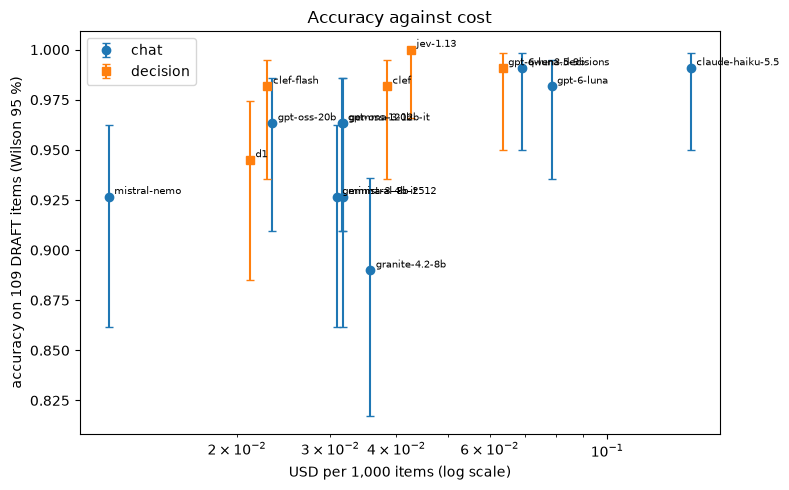

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
for kind, marker in [("chat", "o"), ("decision", "s")]:
    sub = M[M["kind"] == kind]
    ax.errorbar(
        sub["usd_per_1000_items"],
        sub["accuracy"],
        yerr=[sub["accuracy"] - sub["wilson_lo"], sub["wilson_hi"] - sub["accuracy"]],
        fmt=marker,
        capsize=3,
        label=kind,
    )
    for name, r in sub.iterrows():
        ax.annotate(
            name.split("/")[-1],
            (r["usd_per_1000_items"], r["accuracy"]),
            fontsize=7,
            xytext=(4, 2),
            textcoords="offset points",
        )
ax.set_xscale("log")
ax.set_xlabel("USD per 1,000 items (log scale)")
ax.set_ylabel("accuracy on 109 DRAFT items (Wilson 95 %)")
ax.set_title("Accuracy against cost")
ax.legend()
plt.tight_layout()

## Applying the registered decision rule

**Step 1, exclusions.** A model is excluded if its schema-valid rate is below 0.98 or its error
rate is above 2 %.

In [9]:
excluded = M[(M["schema_valid_rate"] < 0.98) | (M["error_rate"] > 0.02)]
eligible = M.drop(excluded.index)
print("excluded:", list(excluded.index) or "none")
excluded[["kind", "schema_valid_rate", "error_rate"]].round(3)

excluded: none


,kind,schema_valid_rate,error_rate


**Step 2, challengers against the reference.** For every eligible model we run McNemar's exact
test on the same 109 items against `openai/gpt-oss-120b`.
- `b`: items the challenger got right and the reference got wrong.
- `c`: the reverse.
- A challenger **replaces** the reference only if p < 0.05 *in its favour* (b > c) and its
  restricted F1 is not lower.

In [10]:
REF = "openai/gpt-oss-120b"
ok_wide = P.pivot_table(index="item_id", columns="model", values="ok", aggfunc="first").astype(bool)


def mcnemar(a: str, b: str) -> tuple[int, int, float]:
    bb = int((ok_wide[a] & ~ok_wide[b]).sum())
    cc = int((~ok_wide[a] & ok_wide[b]).sum())
    p = stats.binomtest(min(bb, cc), bb + cc, 0.5).pvalue if bb + cc else 1.0
    return bb, cc, float(p)


rows_cmp = []
for m in eligible.index:
    if m == REF:
        continue
    b, c, p = mcnemar(m, REF)
    rows_cmp.append(
        {
            "challenger": m,
            "b_challenger_only_right": b,
            "c_reference_only_right": c,
            "p_value": p,
            "significantly_better": p < 0.05 and b > c,
            "significantly_worse": p < 0.05 and c > b,
            "restricted_f1_not_lower": M.loc[m, "restricted_f1"] >= M.loc[REF, "restricted_f1"],
        }
    )
CMP = pd.DataFrame(rows_cmp).set_index("challenger")
winners = CMP[CMP["significantly_better"] & CMP["restricted_f1_not_lower"]]
CMP.round(4)

,b_challenger_only_right,c_reference_only_right,p_value,significantly_better,significantly_worse,restricted_f1_not_lower
challenger,,,,,,
anthropic/claude-haiku-5.5,4,1,0.3750,False,False,False
cloudflare/clef,3,1,0.6250,False,False,True
cloudflare/clef-flash,3,1,0.6250,False,False,True
google/gemma-3-12b-it,3,3,1.0000,False,False,False
google/gemma-3-4b-it,3,7,0.3438,False,False,False
ibm-granite/granite-4.2-8b,3,11,0.0574,False,False,False
liquid/d1,4,6,0.7539,False,False,False
mistralai/ministral-8b-2512,3,7,0.3438,False,False,False
mistralai/mistral-nemo,3,7,0.3438,False,False,False


**Step 3, the choice.** If a challenger won step 2, it is chosen; with several winners, the
cheapest. Otherwise the candidates are the reference plus every eligible model that is not
significantly worse. Among those, choose the cheapest per 1,000 items, then the lowest median
latency.

In [11]:
if len(winners):
    pool = M.loc[winners.index]
    reason = "a challenger beat the reference (McNemar p < 0.05, restricted F1 not lower)"
else:
    non_inferior = [REF] + [m for m in CMP.index if not CMP.loc[m, "significantly_worse"]]
    pool = M.loc[non_inferior]
    reason = "no challenger beat the reference; cheapest among the non-inferior models"
chosen = pool.sort_values(["usd_per_1000_items", "latency_median_s"]).index[0]
print("non-inferior pool:", list(pool.index))
print(f"\nCHOSEN (PRELIMINARY): {chosen}\nreason: {reason}")
print(
    M.loc[
        chosen, ["kind", "accuracy", "restricted_f1", "usd_per_1000_items", "latency_median_s"]
    ].to_string()
)

non-inferior pool: ['openai/gpt-oss-120b', 'anthropic/claude-haiku-5.5', 'cloudflare/clef', 'cloudflare/clef-flash', 'google/gemma-3-12b-it', 'google/gemma-3-4b-it', 'ibm-granite/granite-4.2-8b', 'liquid/d1', 'mistralai/ministral-8b-2512', 'mistralai/mistral-nemo', 'openai/gpt-6-luna', 'openai/gpt-6-luna-decisions', 'openai/gpt-oss-20b', 'qwen/qwen3.5-9b', 'typesafe/jev-1.13']

CHOSEN (PRELIMINARY): mistralai/mistral-nemo
reason: no challenger beat the reference; cheapest among the non-inferior models
kind                      chat
accuracy              0.926606
restricted_f1         0.948454
usd_per_1000_items    0.011451
latency_median_s         0.861


**Step 4, the confidence source for EXC-03.** The Brier score here is the mean squared gap
between the top-label confidence (the probability the model gives its own answer) and whether
the answer was right. Lower is better. ECE groups the items into 10 confidence bins.

The two kinds of confidence differ:
- For a generative model it is a number the model **writes**.
- For a decision model it is a **probability distribution** it returns.

Both are compared on the same footing here.

In [12]:
def calib(g: pd.DataFrame) -> dict:
    g = g.dropna(subset=["confidence"])
    conf = g["confidence"].astype(float).clip(0, 1).to_numpy()
    y = g["ok"].astype(float).to_numpy()
    brier = float(np.mean((conf - y) ** 2))
    bins = np.minimum((conf * 10).astype(int), 9)
    ece = sum(
        (bins == k).mean() * abs(y[bins == k].mean() - conf[bins == k].mean())
        for k in range(10)
        if (bins == k).any()
    )
    return {
        "n_with_confidence": len(g),
        "brier": brier,
        "ece": float(ece),
        "mean_confidence": float(conf.mean()),
        "accuracy_on_those": float(y.mean()),
    }


CAL = pd.DataFrame(
    {m: calib(g) for m, g in P[P["model"].isin(eligible.index)].groupby("model")}
).T.astype(float)
CAL["kind"] = M.loc[CAL.index, "kind"]
best_conf = CAL.sort_values("brier").index[0]
print("lowest Brier (EXC-03 confidence source, PRELIMINARY):", best_conf)
CAL.sort_values("brier").round(4)

lowest Brier (EXC-03 confidence source, PRELIMINARY): qwen/qwen3.5-9b


,n_with_confidence,brier,ece,mean_confidence,accuracy_on_those,kind
qwen/qwen3.5-9b,109.0,0.0097,0.0202,0.9706,0.9908,chat
typesafe/jev-1.13,109.0,0.0102,0.0473,0.9527,1.0000,decision
openai/gpt-6-luna,109.0,0.0149,0.0125,0.9835,0.9817,chat
anthropic/claude-haiku-5.5,109.0,0.0162,0.0672,0.9236,0.9908,chat
openai/gpt-6-luna-decisions,109.0,0.0238,0.0635,0.9325,0.9908,decision
cloudflare/clef,109.0,0.0260,0.0968,0.8848,0.9817,decision
cloudflare/clef-flash,109.0,0.0316,0.1257,0.8637,0.9817,decision
liquid/d1,109.0,0.0317,0.0568,0.9084,0.9450,decision
openai/gpt-oss-120b,109.0,0.0326,0.0250,0.9819,0.9633,chat
openai/gpt-oss-20b,109.0,0.0348,0.0243,0.9876,0.9633,chat


In [13]:
def reliability(model: str) -> pd.DataFrame:
    g = P[P["model"] == model].dropna(subset=["confidence"])
    conf = g["confidence"].astype(float).clip(0, 1)
    b = pd.cut(conf, [0, 0.5, 0.7, 0.8, 0.9, 0.95, 1.0001], right=False)
    return g.groupby(b, observed=True).agg(
        n=("ok", "size"), mean_conf=("confidence", "mean"), accuracy=("ok", "mean")
    )


for m in [best_conf, REF]:
    print(m)
    display(reliability(m).round(3))

qwen/qwen3.5-9b


,n,mean_conf,accuracy
confidence,,,
"[0.95, 1.0)",109,0.971,0.991


openai/gpt-oss-120b


,n,mean_conf,accuracy
confidence,,,
"[0.8, 0.9)",2,0.825,1.00
"[0.9, 0.95)",4,0.923,0.25
"[0.95, 1.0)",103,0.987,0.99


With 109 items most bins hold only a handful of items, so these tables show direction (over- or
under-confidence), not a calibrated curve.

## What the registered rule got wrong

Step 3 treated "not significantly worse" (McNemar p >= 0.05) as if it meant "as good as". With
only 109 items, and few items on which two strong models disagree, McNemar has little power. A
clearly weaker model therefore fails to be *significantly* worse, enters the non-inferior pool,
and wins on price. **Absence of evidence of a difference is not evidence of equivalence.** The
rule's mechanical output above stands as the registered result. It is reported, not overridden.

The fix is a **non-inferiority margin**. A challenger counts as "as good as" the reference only
if the lower end of the 95 % paired bootstrap interval for (challenger − reference) accuracy is
above −δ. The cell below shows, for illustration only, what δ = 2 points would admit on these
items. The corrected rule is registered as E14 **before** it is run on the hardened dev set.
Choosing it on these same items would be exactly the selection bias notebook 04 warns about.

In [14]:
rng = np.random.default_rng(20261009)
ids = list(GOLD)
ref_ok = ok_wide.loc[ids, REF].to_numpy()
B = 5000
idx = rng.integers(0, len(ids), size=(B, len(ids)))
rows_ni = []
for m in eligible.index:
    if m == REF:
        continue
    diff = ok_wide.loc[ids, m].to_numpy().astype(float) - ref_ok.astype(float)
    boot = diff[idx].mean(axis=1)
    lo, hi = np.percentile(boot, [2.5, 97.5])
    rows_ni.append(
        {
            "model": m,
            "acc_diff_vs_ref": diff.mean(),
            "ci_lo": lo,
            "ci_hi": hi,
            "non_inferior_at_2pt": lo > -0.02,
            "usd_per_1000_items": M.loc[m, "usd_per_1000_items"],
        }
    )
NI = pd.DataFrame(rows_ni).set_index("model").sort_values("acc_diff_vs_ref", ascending=False)
print("illustration only (delta = 0.02, 5,000 paired bootstrap resamples):")
NI.round(4)

illustration only (delta = 0.02, 5,000 paired bootstrap resamples):


,acc_diff_vs_ref,ci_lo,ci_hi,non_inferior_at_2pt,usd_per_1000_items
model,,,,,
typesafe/jev-1.13,0.0367,0.0092,0.0734,True,0.0426
anthropic/claude-haiku-5.5,0.0275,-0.0092,0.0644,True,0.1438
openai/gpt-6-luna-decisions,0.0275,0.0000,0.0642,True,0.0635
qwen/qwen3.5-9b,0.0275,0.0000,0.0642,True,0.0691
cloudflare/clef-flash,0.0183,-0.0183,0.0550,True,0.0228
cloudflare/clef,0.0183,-0.0183,0.0550,True,0.0384
openai/gpt-6-luna,0.0183,-0.0183,0.0550,True,0.0785
openai/gpt-oss-20b,0.0000,-0.0459,0.0459,False,0.0233
google/gemma-3-12b-it,0.0000,-0.0459,0.0459,False,0.0318


## Where the models differ: traps, languages, hard items

In [15]:
P["trap_kind"] = P["item_id"].map(lambda i: (GOLD[i].get("trap") or "plain:").split(":")[0])
P["language"] = P["item_id"].map(lambda i: GOLD[i]["language"])
first = P["model"].iloc[0]
for col in ["trap_kind", "language"]:
    t = P.pivot_table(index=col, columns="model", values="ok", aggfunc="mean")
    t.insert(0, "n", P[P["model"] == first].groupby(col).size())
    display(t.round(2))

model,n,anthropic/claude-haiku-5.5,cloudflare/clef,cloudflare/clef-flash,google/gemma-3-12b-it,google/gemma-3-4b-it,ibm-granite/granite-4.2-8b,liquid/d1,mistralai/ministral-8b-2512,mistralai/mistral-nemo,openai/gpt-6-luna,openai/gpt-6-luna-decisions,openai/gpt-oss-120b,openai/gpt-oss-20b,qwen/qwen3.5-9b,typesafe/jev-1.13
trap_kind,,,,,,,,,,,,,,,,
boundary,21,0.95,0.9,0.9,0.86,0.90,0.81,0.86,0.90,0.86,0.95,0.95,0.86,0.95,0.95,1.0
named,6,1.00,1.0,1.0,1.00,1.00,1.00,1.00,1.00,0.83,1.00,1.00,1.00,1.00,1.00,1.0
plain,68,1.00,1.0,1.0,1.00,0.94,0.91,0.97,0.91,0.96,0.99,1.00,0.99,0.96,1.00,1.0
variant,14,1.00,1.0,1.0,0.93,0.86,0.86,0.93,1.00,0.93,1.00,1.00,1.00,1.00,1.00,1.0


model,n,anthropic/claude-haiku-5.5,cloudflare/clef,cloudflare/clef-flash,google/gemma-3-12b-it,google/gemma-3-4b-it,ibm-granite/granite-4.2-8b,liquid/d1,mistralai/ministral-8b-2512,mistralai/mistral-nemo,openai/gpt-6-luna,openai/gpt-6-luna-decisions,openai/gpt-oss-120b,openai/gpt-oss-20b,qwen/qwen3.5-9b,typesafe/jev-1.13
language,,,,,,,,,,,,,,,,
de,10,1.00,1.00,1.00,1.00,1.00,0.80,0.80,0.90,0.70,1.00,1.00,1.00,0.90,1.00,1.0
en,61,1.00,0.97,0.97,0.97,0.93,0.90,0.97,0.95,0.95,0.97,0.98,0.93,0.95,0.98,1.0
es,8,1.00,1.00,1.00,1.00,0.75,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.0
fr,9,1.00,1.00,1.00,1.00,0.89,1.00,1.00,0.89,1.00,1.00,1.00,1.00,1.00,1.00,1.0
ja,13,0.92,1.00,1.00,0.85,0.92,0.77,0.85,0.77,0.85,1.00,1.00,1.00,1.00,1.00,1.0
pt,8,1.00,1.00,1.00,1.00,1.00,0.88,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.0


In [16]:
wide = P.pivot_table(index="item_id", columns="model", values="predicted_category", aggfunc="first")
wrong = (~ok_wide).sum(axis=1).sort_values(ascending=False)
hard = wrong[wrong > 0]
print(f"{len(hard)} of {len(GOLD)} items are missed by at least one model; by how many models:")
pd.DataFrame(
    {
        "models_wrong": hard,
        "description": [GOLD[i]["description"] for i in hard.index],
        "draft_label": [GOLD[i]["proposed_category"] for i in hard.index],
        "debatable": ["debatable" in GOLD[i]["rationale"].lower() for i in hard.index],
        "most_common_wrong": [
            wide.loc[i][wide.loc[i] != GOLD[i]["proposed_category"]].value_counts().index[0]
            if (wide.loc[i] != GOLD[i]["proposed_category"]).any()
            else ""
            for i in hard.index
        ],
    }
).head(25)

30 of 109 items are missed by at least one model; by how many models:


,models_wrong,description,draft_label,debatable,most_common_wrong
item_id,,,,,
DEV-056,9,Spa voucher for two people,gift_card,False,personal_care
DEV-082,5,"Bahnfahrkarte München–Berlin, 2. Klasse",ground_transport,False,airfare
DEV-072,5,Overnight courier envelope to client,office_supplies,False,service_fee
DEV-053,5,菓子折り 取引先へ,gift,False,food_beverage
DEV-009,5,本みりん 500ml 瓶,alcohol,True,food_beverage
DEV-108,3,Visa application fee,other,False,service_fee
DEV-106,3,"Smartphone 128 GB, unlocked",other,False,personal_electronics
DEV-070,2,ノートパソコンスタンド アルミ製,computer_accessory,False,personal_electronics
DEV-085,2,"Checked bag fee, first bag",airfare,False,service_fee


## Write the results

In [17]:
out = {
    "experiment": "E13",
    "status": "PRELIMINARY: DRAFT labels",
    "n_items": len(DEV),
    "reference": REF,
    "excluded": list(excluded.index),
    "mcnemar_vs_reference": CMP.reset_index().to_dict("records"),
    "chosen_classifier": chosen,
    "choice_reason": reason,
    "exc03_confidence_source": best_conf,
    "models": M.reset_index().rename(columns={"index": "model"}).to_dict("records"),
    "calibration": CAL.reset_index().rename(columns={"index": "model"}).to_dict("records"),
}
_ = (EXP / "results" / "05_results.json").write_text(json.dumps(out, indent=1, default=float))
print("wrote results/05_results.json and results/05_predictions.jsonl")

wrote results/05_results.json and results/05_predictions.jsonl


## Reading this honestly

- **N is 109 items.** The minimum detectable difference at this N (computed below, same method
  as notebook 04) means most gaps between strong models above are noise. The McNemar table,
  not the ranking, is what the decision uses.
- **The labels are DRAFT** and written by the same assistant as the prompts. A model that
  disagrees on an item marked *debatable* may be right.
- **Selection bias.** The chosen model looks better here than it will on new data, because
  it was picked on these items. The 28 real receipts are run only once, with the finalist.
- **Determinism.** Decision models are reported to vary between calls, and E11 showed that
  gpt-oss's raw text varies too. Every answer used here is cached, so the pipeline's output
  stays reproducible.

In [18]:
def power_two_prop(p1: float, p2: float, n: int, alpha: float = 0.05) -> float:
    pbar = (p1 + p2) / 2
    se0 = math.sqrt(2 * pbar * (1 - pbar) / n)
    se1 = math.sqrt(p1 * (1 - p1) / n + p2 * (1 - p2) / n)
    return float(stats.norm.cdf((abs(p1 - p2) - stats.norm.ppf(1 - alpha / 2) * se0) / se1))


base = min(float(M["accuracy"].max()), 0.95)
mdd = next(
    d / 1000 for d in range(1, 1000) if power_two_prop(base - d / 1000, base, len(DEV)) >= 0.8
)
print(
    f"N={len(DEV)}, around {base:.2f} accuracy: minimum detectable difference = {mdd:.3f} "
    "(unpaired, alpha 0.05, power 0.8)"
)

N=109, around 0.95 accuracy: minimum detectable difference = 0.118 (unpaired, alpha 0.05, power 0.8)
